# Exercise 5

# 5.1

In [98]:
from autograd import grad
# gradient descent function - inputs: g (input function), alpha (steplength parameter), max_its (maximum number of iterations), w (initialization)
def gradient_descent(g,alpha,max_its,w):
    # compute gradient module using autograd
    gradient = grad(g)

    # run the gradient descent loop
    weight_history = [w]           # container for weight history
    cost_history = [g(w)]          # container for corresponding cost function history
    for k in range(max_its):
        # evaluate the gradient, store current weights and cost function value
        grad_eval = gradient(w)

        # take gradient descent step
        w = w - alpha*grad_eval
        
        # record weight and cost
        weight_history.append(w)
        cost_history.append(g(w))
    return weight_history, cost_history

In [99]:
# load in dataset
import autograd.numpy as np
from autograd import grad
data = np.loadtxt('3class_data.csv',delimiter = ',')

# get input/output pairs
x = data[:-1,:]
y = data[-1:,:] 

In [100]:
# compute linear combination of input points
def model(x,w):
    a = w[0] + np.dot(x.T,w[1:])
    return a.T

lam = 10**-5  # our regularization paramter
def multiclass_perceptron(w):
    # pre-compute predictions on all points
    all_evals = model(x,w)
    # compute maximum across data points
    a = np.max(all_evals,axis = 0)
    # compute cost in compact form using numpy broadcasting
    b = all_evals[y.astype(int).flatten(),np.arange(np.size(y))]
    cost = np.sum(a - b)
    # add regularizer
    cost = cost + lam*np.linalg.norm(w[1:,:],"fro")**2
    # return average
    return cost/float(np.size(y))

In [101]:
# parameters for gradient descent
max_its = 1000
w = 0.1*np.random.randn(3,3) # bias + weights for each feature
alpha = 0.1
weight_history, cost_history = gradient_descent(multiclass_perceptron,alpha,max_its,w)

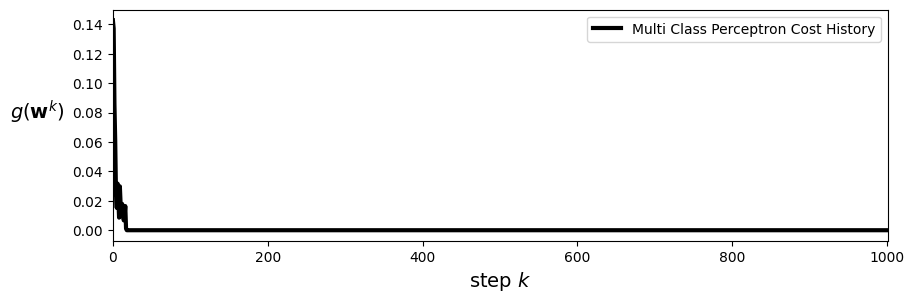

In [102]:
# plot cost function history
from MLRPlotting import static_plotter
# plotting the cost histories

# import custom plotting tools
static_plotter = static_plotter.Visualizer()
static_plotter.plot_cost_histories([cost_history],start=0,points=False,labels=[r'Multi Class Perceptron Cost History'])

In [103]:
# evaluation of the trained model
final_weights = weight_history[-1]
preds = model(x,final_weights)
pred_labels = np.argmax(preds,axis=0)
accuracy = np.mean(pred_labels == y.flatten())
print("Final training accuracy: %.2f%%"%(accuracy*100))

Final training accuracy: 100.00%


The model has an accuracy of 100% so its as good as the one in the textbook.

# 5.2

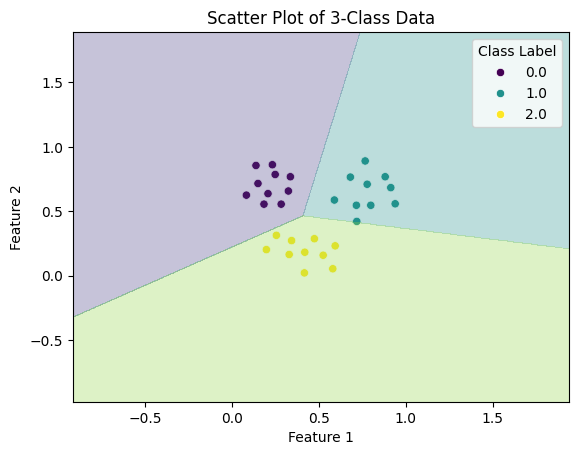

In [104]:
import seaborn as sns
import matplotlib.pyplot as plt
# create a scatter plot of the data points colored by their class labels
sns.scatterplot(x=x[0,:], y=x[1,:], hue=y.flatten(), palette='viridis', legend='full')
# plot the decision boundaries
x_min, x_max = x[0,:].min() - 1, x[0,:].max() + 1
y_min, y_max = x[1,:].min() - 1, x[1,:].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 1000), np.linspace(y_min, y_max, 1000))
Z = model(np.array([xx.ravel(), yy.ravel()]), final_weights)
Z = np.argmax(Z, axis=0).reshape(xx.shape)
plt.contourf(xx, yy, Z, alpha=0.3, levels=np.arange(-0.5, 3.5, 1), cmap='viridis')
plt.title('Scatter Plot of 3-Class Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend(title='Class Label')
plt.show()

In [105]:
final_weights

array([[ 0.02028637, -0.02315226,  0.06417727],
       [-0.09505657,  0.04919222,  0.02178606],
       [ 0.10932385,  0.07613115, -0.08754443]])